# Fast Single-Image Super-Resolution (×4)

Lab 7 mini project for **EEP5C16 Deep Learning and its Applications**, Trinity College Dublin.

A small convolutional network that upscales 32×32 RGB image patches to 128×128 (×4), fast enough for real-time video.

| | PSNR | SSIM | Parameters | Time per frame |
|---|---|---|---|---|
| Bicubic interpolation (baseline) | 25.48 dB | 0.606 | 0 | – |
| **This model** | **26.78 dB** | **0.677** | **245,507** | **0.47 ms** |

That is **+1.30 dB PSNR** and **+0.071 SSIM** over bicubic. The model uses about 5% of the 5M parameter limit and runs about 70× faster than the 33 ms real-time target (≈2,100 frames per second).

---

## The task

- **Goal:** upsample 32×32 image patches to 128×128 (×4), as close to real time as possible. Real time here means a 30 fps video stream, so about 0.03 s per frame.
- **Data:** a provided dataset of high-resolution images. These have to be downsampled to make the network's inputs, then split into training and test sets.
- **Model:** a `SuperResolutionModel` class in `models.py`, saved as `model.pth`, with fewer than 5 million parameters. Inputs and outputs are in (B, C, H, W) order with values in [0, 1].
- **Evaluation:** PSNR, SSIM and parameter count, plus a discussion of efficiency. The brief also suggests using the fact that the eye is more sensitive to brightness (luminance) than to colour.

## Approach

**Residual learning.** Bicubic interpolation already gets the colours and rough shapes right, but it looks blurry. So the network only predicts the missing detail, which is added on top of the bicubic image:

$$\hat{y} = \text{bicubic}(x) + f_\theta(x)$$

This is the same idea as ResNet's skip connections, applied to super-resolution in VDSR (Kim et al., 2016).

**Speed.** The convolutions work on the small 32×32 image. A convolution's cost grows with image area, so this is 16× cheaper than working at 128×128. The image is only enlarged at the end, by two learned transposed convolutions.

### Architecture (`models.py`)

| Layer | Output size |
|---|---|
| Input | 3 × 32 × 32 |
| `conv1`–`conv4`: 3×3 conv (`padding='same'`) + ReLU | 64 × 32 × 32 |
| `up1`: transposed conv (kernel 4, stride 2) + ReLU | 64 × 64 × 64 |
| `up2`: transposed conv (kernel 4, stride 2) + ReLU | 64 × 128 × 128 |
| `conv_out`: 3×3 conv (no ReLU, so the detail can be negative) | 3 × 128 × 128 |
| Output = bicubic(input) + detail, clamped to [0, 1] when evaluating | 3 × 128 × 128 |

The last layer starts with very small weights, so the untrained model outputs roughly the bicubic image and training starts from the baseline.

### Data

- **Dataset:** 17,354 high-resolution 128×128 images, with pixel values scaled from 0–255 to [0, 1].
- **Inputs:** made by downsampling each image ×4 with `skimage.transform.rescale` (anti-aliasing on).
- **Split:** 90/10 into training and validation sets with `sklearn.model_selection.train_test_split(random_state=42)`, as in Lab 5.
- **Augmentation:** random left-right flips during training.

### Training

| Setting | Value | Why |
|---|---|---|
| Loss | L1 | Recommended for super-resolution by EDSR (Lim et al., 2017); scored the same as MSE in my runs |
| Optimiser | Adam, learning rate 0.001 | The starter notebook's choice |
| Learning-rate schedule | Cosine annealing over 30 epochs: $\eta_t=\tfrac12\eta_{max}\left(1+\cos\frac{\pi t}{T}\right)$ | Removes the jitter at the end of training (Loshchilov & Hutter, 2017; Handout 07) |
| Epochs | 30 | Validation PSNR levels off after about 20–30 epochs |
| Batch size | 32 | The starter notebook's choice |

## Hardware and software

| | |
|---|---|
| GPU | NVIDIA GeForce RTX 5070 (12 GB) |
| Software | PyTorch 2.14.1 (CUDA 13.0), Python 3.14, Windows, VS Code |
| Training time | About 4.6 minutes for 30 epochs (final model) |
| Timing method | One 32×32 frame at a time (batch size 1), after 10 warm-up runs, with `torch.cuda.synchronize()` |

Timings will be different on other hardware, such as Colab's T4 or the marking server.

---

## Development process

Each run changed one thing, chosen from the result of the previous run. All runs from v1 to v11 used the same random seed and the same train/validation split, so the differences come from the change being tested.

**Earlier exploration.** My first design was more complex: ResNet-style residual blocks with batch normalisation, AdamW and cosine decay. Models from 118k to 912k parameters all reached about 26.6–26.7 dB, so a model 15× bigger gained only about 0.1 dB. I restarted from the simple model above and added complexity only where an experiment showed it helped.

| Run | Change | Params | PSNR (dB) | SSIM | ms/frame | Result |
|---|---|---|---|---|---|---|
| – | bicubic baseline | 0 | 25.48 | 0.606 | – | the bar to beat |
| v1 | baseline: 32 channels, MSE, 10 epochs | 62,339 | 26.62 | 0.668 | 0.47 | +1.14 dB over bicubic, but still improving at epoch 10 |
| v2 | L1 loss + 30 epochs | 62,339 | 26.70 | 0.673 | 0.42 | L1 ≈ MSE at equal epochs; longer training +0.07 dB, then plateaus |
| v3 | 64 channels | 245,507 | 26.78 | 0.677 | 0.45 | +0.09 dB for 4× the parameters |
| v4 | 128 channels | 974,339 | 26.79 | 0.677 | 0.54 | +0.01 dB (noise): width has saturated, so keep 64 |
| v5 | 64 ch + cosine learning rate | 245,507 | 26.79 | 0.677 | 0.48 | No gain, but removes the end-of-training jitter: kept |
| v6 | 8 conv layers | 393,219 | 26.74 | 0.674 | 0.67 | Worse, with a higher training loss: an optimisation problem, not overfitting |
| v7 | 8 layers + residual connections | 393,219 | 26.79 | 0.677 | 0.77 | ResNet fix works, but only matches 4 layers: keep v5 |
| v8 | v5 without the bicubic shortcut (ablation) | 245,507 | 26.56 | 0.668 | 0.42 | −0.23 dB, started below bicubic and trained unstably: the shortcut matters most |
| v9 | v5 without flips (ablation) | 245,507 | 26.73 | 0.675 | 0.45 | −0.06 dB: small gain, free at inference, kept |
| **v10** | **final model (v5 settings)** | **245,507** | **26.78** | **0.677** | **0.47** | Rerun: 26.78 / 26.78, so reproducible to about ±0.01 dB |
| v11 | v10, brightness-only detail | 244,353 | 26.73 | 0.674 | 0.45 | Keeps 96% of the gain with 1 output channel |

### Key findings

1. **The bicubic shortcut is the most important design choice.** Without it the network has to learn the whole image: it starts 3 dB below bicubic, trains unstably, and ends 0.23 dB worse.
2. **Width helps up to 64 channels, then saturates.** Going from 64 to 128 channels quadrupled the parameters for +0.01 dB.
3. **Deeper plain networks train worse.** 8 layers had a *higher* training loss than 4. That is the degradation problem that ResNet's skip connections solve. With skip connections it trained properly, but only matched 4 layers.
4. **Speed depends more on the number of layers than on width** at batch size 1. Doubling the width added 0.09 ms, but adding 4 layers added 0.2–0.3 ms, because a single small image leaves the GPU mostly idle, so each layer costs a roughly fixed time.
5. **Brightness carries almost all of the useful detail.** Predicting one brightness-detail map and adding it equally to R, G and B changes only luma, since $Y = 0.299R + 0.587G + 0.114B$ and the weights sum to 1. This kept 96% of the gain (+1.25 vs +1.30 dB) with no visible difference. This uses the brief's luminance hint, as RAISR (Romano et al., 2017) and SRCNN (Dong et al., 2016) do. v10 (full RGB) was kept as the submitted model because the server scores RGB PSNR.
6. **Everything hits the same ~26.8 dB ceiling** (width, depth and learning rate). The limit is the information lost in downsampling. With a pixel-wise loss, the best a model can do is predict the *average* plausible detail, which is smooth. GAN-based methods such as SRGAN (Ledig et al., 2017) produce more realistic texture, at the cost of a lower PSNR. That is possible future work.

---

## Repository contents

```
models.py          SuperResolutionModel (final architecture)
Lab 7.ipynb        data pre-processing, training, evaluation, saving, explained step by step
model.pth          trained model (torch.save of the whole model)
requirements.txt   Python packages
dev_log.csv        log of every development run (v1-v11)
```
The dataset is not included. The notebook downloads it into `data/` on the first run.

## How to run

1. **Install PyTorch with GPU support**, then the other packages:
   ```
   pip install torch torchvision --index-url https://download.pytorch.org/whl/cu130
   pip install -r requirements.txt
   ```
2. **Open `Lab 7.ipynb` and run all cells.** The notebook downloads the dataset, trains the model, and saves `model.pth`.
3. **To load the trained model:**
   ```python
   import torch
   from models import SuperResolutionModel
   model = torch.load('model.pth', weights_only=False)
   model.eval()
   high_res = model(low_res)   # (B, 3, 32, 32) in [0, 1] -> (B, 3, 128, 128)
   ```

## References

- Lab 7 starter notebook; F. Pitié, 4C16/5C16 lecture handouts 04–07 and 10, Trinity College Dublin.
- J. Kim, J. K. Lee, K. M. Lee. *Accurate Image Super-Resolution Using Very Deep Convolutional Networks (VDSR).* CVPR 2016.
- B. Lim, S. Son, H. Kim, S. Nah, K. M. Lee. *Enhanced Deep Residual Networks for Single Image Super-Resolution (EDSR).* CVPR Workshops 2017.
- K. He, X. Zhang, S. Ren, J. Sun. *Deep Residual Learning for Image Recognition.* CVPR 2016.
- I. Loshchilov, F. Hutter. *SGDR: Stochastic Gradient Descent with Warm Restarts.* ICLR 2017.
- Y. Romano, J. Isidoro, P. Milanfar. *RAISR: Rapid and Accurate Image Super Resolution.* IEEE Transactions on Computational Imaging, 2017.
- C. Dong, C. C. Loy, K. He, X. Tang. *Image Super-Resolution Using Deep Convolutional Networks (SRCNN).* IEEE TPAMI, 2016.
- C. Ledig et al. *Photo-Realistic Single Image Super-Resolution Using a Generative Adversarial Network (SRGAN).* CVPR 2017.
- A. Odena, V. Dumoulin, C. Olah. *Deconvolution and Checkerboard Artifacts.* Distill, 2016.
- Z. Wang, A. C. Bovik, H. R. Sheikh, E. P. Simoncelli. *Image Quality Assessment: From Error Visibility to Structural Similarity.* IEEE Transactions on Image Processing, 2004.
- G. Berger et al. *QuickSRNet: Plain Single-Image Super-Resolution Architecture for Faster Inference on Mobile Platforms.* CVPR Workshops 2023.

# Download the dataset
The dataset is downloaded into a `data` folder next to this notebook the first time (~617MB). It is kept outside the lab's code folder, as the instructions ask.

In [1]:
import os
import urllib.request

dataset_url = 'https://tcddeeplearning.blob.core.windows.net/deeplearning202324/hr_images.npz'
dataset_path = 'data/dataset.npz'

if not os.path.exists(dataset_path):
    os.makedirs('data', exist_ok=True)
    print('Downloading dataset...')
    urllib.request.urlretrieve(dataset_url, dataset_path)
    print('Download complete.')
else:
    print('Dataset already downloaded.')

Dataset already downloaded.


# Import necessary libraries

In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt
import sklearn.model_selection                    # train_test_split (as in lab 5)
from skimage.transform import rescale             # downsampling (suggested in the lab 7 notebook)

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchmetrics.functional import structural_similarity_index_measure as ssim

# Import our model definition
from models import SuperResolutionModel

# Use the GPU if there is one
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

Using device: cuda


# Dataset pre-processing

**1. Load and scale.** The images are 8-bit (0 to 255), but the inputs and outputs must be in $[0, 1]$, so every pixel is divided by 255.

**2. Train/validation split.** 10% of the images are held back as a validation set. The model never trains on them, so they show how well it works on new images (Handout 04). `train_test_split` with a fixed `random_state` is the same as in Lab 5, so the split is the same every time.

**3. Downsample.** Each $128\times128$ image is shrunk $\times4$ to $32\times32$ with `rescale`, as suggested in the instructions. `anti_aliasing=True` blurs the image slightly before shrinking, like a real camera. Without it, fine patterns turn into false patterns (aliasing).

The low-res image is the **input** and the original image is the **target**. The downsampling is done in chunks of 1000 images to save memory.

In [3]:
hr_images = np.load(dataset_path)['hr_images']
# Your input/output images should have pixel values in the range [0, 1]
hr_images = hr_images.astype('float32') / 255.0
print('All images:', hr_images.shape)

# 90/10 split into training and validation sets
hr_train, hr_val = sklearn.model_selection.train_test_split(hr_images, test_size=0.1, random_state=42)

# Downsample each image x4 with rescale
def downsample(images):
    small = []
    for i in range(0, len(images), 1000):
        chunk = rescale(images[i:i + 1000], (1, 0.25, 0.25), channel_axis=-1, anti_aliasing=True)
        small.append(chunk.astype('float32'))
    return np.concatenate(small)

lr_train = downsample(hr_train)
lr_val = downsample(hr_val)

print('Training:  ', lr_train.shape, '->', hr_train.shape)
print('Validation:', lr_val.shape, '->', hr_val.shape)

All images: (17354, 128, 128, 3)
Training:   (15618, 32, 32, 3) -> (15618, 128, 128, 3)
Validation: (1736, 32, 32, 3) -> (1736, 128, 128, 3)


# Defining the Dataset Generator and Dataloader

The `Dataset` returns one (low-res, high-res) pair at a time. The images are permuted from (H, W, C) to (C, H, W), because that is the order PyTorch layers expect.

**Data augmentation (Handout 07).** Training pairs are randomly flipped left-right. A flipped picture is still a realistic picture, so this gives the network more variety for free. The same flip is applied to the input and the target so they still match. Validation images are not flipped.

The `DataLoader` groups the pairs into mini-batches of 32 and shuffles the training set every epoch (Handout 05).

In [4]:
class SuperResolutionDataset(Dataset):
    def __init__(self, lr_images, hr_images, flip=False):
        # numpy (N, H, W, C) -> torch (N, C, H, W)
        self.lr_images = torch.from_numpy(lr_images).permute(0, 3, 1, 2)
        self.hr_images = torch.from_numpy(hr_images).permute(0, 3, 1, 2)
        self.flip = flip

    def __len__(self):
        return len(self.hr_images)

    def __getitem__(self, idx):
        lr = self.lr_images[idx]
        hr = self.hr_images[idx]
        if self.flip and torch.rand(1).item() < 0.5:
            lr = torch.flip(lr, dims=[2])     # flip left-right
            hr = torch.flip(hr, dims=[2])
        return lr, hr

training_dataset = SuperResolutionDataset(lr_train, hr_train, flip=True)
validation_dataset = SuperResolutionDataset(lr_val, hr_val)

training_dataloader = DataLoader(training_dataset, batch_size=32, shuffle=True)
validation_dataloader = DataLoader(validation_dataset, batch_size=128, shuffle=False)

print('Training images:  ', len(training_dataset))
print('Validation images:', len(validation_dataset))

Training images:   15618
Validation images: 1736


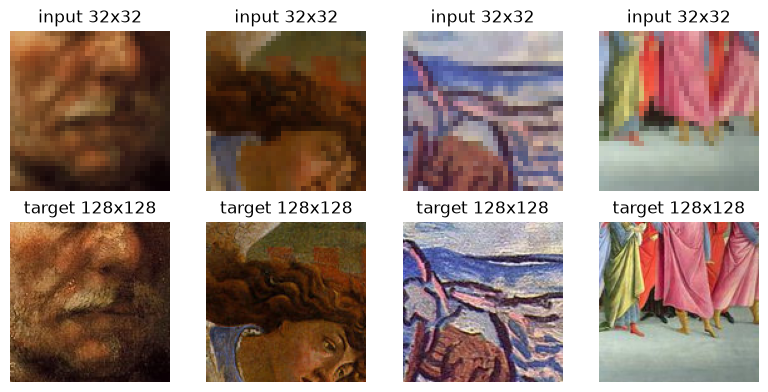

In [5]:
# Look at a few pairs
plt.figure(figsize=(8, 4))
for i in range(4):
    lr, hr = validation_dataset[i]
    plt.subplot(2, 4, i + 1)
    plt.imshow(lr.permute(1, 2, 0))
    plt.title('input 32x32')
    plt.axis('off')
    plt.subplot(2, 4, i + 5)
    plt.imshow(hr.permute(1, 2, 0))
    plt.title('target 128x128')
    plt.axis('off')
plt.tight_layout()
plt.show()

# The model (`models.py`)

| Layer | What it does | Output size |
|---|---|---|
| bicubic upscale of the input | the starting image (no learning) | $3\times128\times128$ |
| `conv1` to `conv4`: 3x3 convolutions + ReLU | learn edge and texture features (Handout 06) | $64\times32\times32$ |
| `up1`, `up2`: transposed convolutions + ReLU | enlarge the features $\times2$ each (Handout 06) | $64\times64\times64$, then $64\times128\times128$ |
| `conv_out`: 3x3 convolution | turns the features into a 3-channel detail image | $3\times128\times128$ |
| output | bicubic + detail, clamped to $[0,1]$ when evaluating | $3\times128\times128$ |

**Why these choices:**
- **`padding='same'`** keeps the $32\times32$ size through the 3x3 convolutions, as in Lab 5.
- **ReLU** $=\max(0, z)$ adds non-linearity and avoids the vanishing gradients of sigmoid/tanh (Handout 05).
- **Transposed convolution** inserts zeros between pixels and then convolves, so the network *learns* how to fill in the new pixels (Handout 06). The output size is
  $$\text{out} = (\text{in}-1)\times\text{stride} - 2\times\text{padding} + \text{kernel} = (32-1)\times2 - 2 + 4 = 64.$$
  A kernel of 4 with stride 2 means every output pixel gets the same number of contributions, which avoids checkerboard patterns (Odena et al., 2016).
- **No ReLU on the last layer**, because the detail must be able to be negative (darken as well as brighten).
- **The last layer starts with tiny weights**, so the untrained model outputs roughly the bicubic image and training starts from a good baseline.
- **No pooling and no fully connected layers** (unlike Lab 5). The output is an image, not a class, so every pixel's position has to be kept.

**Parameters** (weights + biases), with 64 channels:

| Layers | Calculation | Parameters |
|---|---|---|
| `conv1` | $3\times64\times3\times3 + 64$ | 1,792 |
| `conv2`, `conv3`, `conv4` | $3\times(64\times64\times3\times3 + 64)$ | 110,784 |
| `up1`, `up2` | $2\times(64\times64\times4\times4 + 64)$ | 131,200 |
| `conv_out` | $64\times3\times3\times3 + 3$ | 1,731 |
| **total** | | **245,507** (about 5% of the 5M limit) |

In [6]:
sr_model = SuperResolutionModel()

def count_model_parameters(model):
    return sum(p.numel() for p in model.parameters())

print('Parameters:', count_model_parameters(sr_model))

# check the output size
test_input = torch.rand(1, 3, 32, 32)
print('Input: ', test_input.shape)
print('Output:', sr_model(test_input).shape)

Parameters: 245507
Input:  torch.Size([1, 3, 32, 32])
Output: torch.Size([1, 3, 128, 128])


# How the results are measured

**PSNR** (peak signal-to-noise ratio) is the mean squared error on a log scale, in decibels. For images in $[0, 1]$:

$$\text{MSE} = \frac{1}{N}\sum_{i}(\hat{y}_i - y_i)^2 \qquad \text{PSNR} = 10\log_{10}\frac{1}{\text{MSE}}$$

Higher is better: +1 dB means about 21% less squared error, since $10^{-0.1} \approx 0.79$. It is computed for each image, then averaged.

**SSIM** (structural similarity, Wang et al., 2004) compares local brightness, contrast and structure. It is between 0 and 1, and higher is better. It is closer to what looks right to a person. Both metrics are used by the server, and Handout 04 says to always use more than one metric.

**Baseline.** Plain bicubic upscaling, with no learning. The model is only useful if it beats this.

In [7]:
def psnr(pred, target):
    mse = torch.mean((pred - target) ** 2, dim=(1, 2, 3))    # one MSE per image
    return 10 * torch.log10(1.0 / mse)

def evaluate(upscale):
    # average PSNR and SSIM over the validation set, for any upscaling function
    total_psnr = 0.0
    total_ssim = 0.0
    with torch.no_grad():
        for lr, hr in validation_dataloader:
            lr = lr.to(device)
            hr = hr.to(device)
            pred = upscale(lr)
            total_psnr += psnr(pred, hr).sum().item()
            total_ssim += ssim(pred, hr, data_range=1.0).item() * len(lr)
    return total_psnr / len(validation_dataset), total_ssim / len(validation_dataset)

def bicubic(lr):
    return torch.clamp(F.interpolate(lr, scale_factor=4, mode='bicubic', align_corners=False), 0, 1)

bicubic_psnr, bicubic_ssim = evaluate(bicubic)
print(f'Bicubic baseline: PSNR {bicubic_psnr:.2f} dB, SSIM {bicubic_ssim:.4f}')

c:\Users\FOCONNO1\venvs\sr-env\Lib\site-packages\torchmetrics\utilities\prints.py:70: FutureWarning: Importing `spectral_angle_mapper` from `torchmetrics.functional` was deprecated and will be removed in 2.0. Import `spectral_angle_mapper` from `torchmetrics.image` instead.
  _future_warning(


Bicubic baseline: PSNR 25.39 dB, SSIM 0.6062


# Training

**Loss: L1** (mean absolute error):
$$L_1 = \frac{1}{N}\sum_i |\hat{y}_i - y_i| \qquad \text{vs.} \qquad \text{MSE} = \frac{1}{N}\sum_i (\hat{y}_i - y_i)^2$$
MSE squares the errors, so when the model is unsure it plays safe by predicting the average, which looks blurry. L1 punishes all errors in proportion. EDSR (Lim et al., 2017) found that L1 trains better for super-resolution. In my runs, L1 and MSE scored about the same.

**Optimiser: Adam, learning rate 0.001** (the instructions' choice). Adam adapts the step size for each weight, using running averages of the gradient and of its square (Handout 05).

**Learning rate: cosine annealing** (Handout 07; Loshchilov & Hutter, 2017), the same as in Lab 5. The learning rate starts at $\eta_{max}=0.001$ and follows half a cosine down to 0 over the $T$ epochs:
$$\eta_t = \frac{1}{2}\,\eta_{max}\left(1 + \cos\frac{\pi\, t}{T}\right)$$
At $t=0$, $\cos 0 = 1$, so $\eta = \eta_{max}$. At $t=T$, $\cos\pi = -1$, so $\eta = 0$. Big steps early make fast progress; small steps at the end let the weights settle instead of bouncing around. Without it, my validation PSNR jittered at the end of training.

**Epochs: 30.** In my runs the validation PSNR stopped improving after about 20–30 epochs.

**Each step** (Handout 05): forward pass → loss → `zero_grad()` (PyTorch adds gradients up, so they must be cleared first) → `backward()` (backpropagation) → `step()` (update the weights). `train()` and `eval()` switch the model between training and evaluation mode; in evaluation mode the output is clamped to $[0,1]$.

In [8]:
num_epochs = 30

torch.manual_seed(0)                    # same starting weights every time
sr_model = SuperResolutionModel()
criterion = nn.L1Loss() # Define your loss here
optimizer = optim.Adam(sr_model.parameters(), lr=0.001) # Choose an optimiser
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)

# Move model to GPU if available
sr_model.to(device)

train_losses = []
val_psnrs = []
start_time = time.time()

# Define your training loop
for epoch in range(num_epochs):
    sr_model.train()  # Set model to training mode
    total_loss = 0

    for batch_idx, (lr_images, hr_images) in enumerate(training_dataloader):
        lr_images = lr_images.to(device)
        hr_images = hr_images.to(device)

        outputs = sr_model(lr_images)             # forward pass
        loss = criterion(outputs, hr_images)      # how wrong the output is
        optimizer.zero_grad()                     # clear old gradients
        loss.backward()                           # backpropagation
        optimizer.step()                          # update the weights
        total_loss += loss.item()

    scheduler.step()                              # lower the learning rate once per epoch

    sr_model.eval()
    val_psnr, val_ssim = evaluate(sr_model)
    train_losses.append(total_loss / len(training_dataloader))
    val_psnrs.append(val_psnr)
    print(f'Epoch {epoch + 1}: loss {train_losses[-1]:.5f}, val PSNR {val_psnr:.2f} dB, SSIM {val_ssim:.4f}')

print(f'Training took {(time.time() - start_time) / 60:.1f} minutes')

Epoch 1: loss 0.03857, val PSNR 26.40 dB, SSIM 0.6641
Epoch 2: loss 0.03698, val PSNR 26.46 dB, SSIM 0.6690
Epoch 3: loss 0.03676, val PSNR 26.51 dB, SSIM 0.6689
Epoch 4: loss 0.03665, val PSNR 26.51 dB, SSIM 0.6662
Epoch 5: loss 0.03655, val PSNR 26.55 dB, SSIM 0.6696
Epoch 6: loss 0.03642, val PSNR 26.60 dB, SSIM 0.6725
Epoch 7: loss 0.03631, val PSNR 26.57 dB, SSIM 0.6704
Epoch 8: loss 0.03629, val PSNR 26.62 dB, SSIM 0.6744
Epoch 9: loss 0.03618, val PSNR 26.63 dB, SSIM 0.6752
Epoch 10: loss 0.03619, val PSNR 26.61 dB, SSIM 0.6734
Epoch 11: loss 0.03610, val PSNR 26.64 dB, SSIM 0.6765
Epoch 12: loss 0.03608, val PSNR 26.64 dB, SSIM 0.6766
Epoch 13: loss 0.03607, val PSNR 26.66 dB, SSIM 0.6754
Epoch 14: loss 0.03601, val PSNR 26.65 dB, SSIM 0.6765
Epoch 15: loss 0.03598, val PSNR 26.67 dB, SSIM 0.6757
Epoch 16: loss 0.03604, val PSNR 26.64 dB, SSIM 0.6765
Epoch 17: loss 0.03600, val PSNR 26.69 dB, SSIM 0.6748
Epoch 18: loss 0.03601, val PSNR 26.68 dB, SSIM 0.6758
Epoch 19: loss 0.03

# Results

**Training curves.** The loss should fall, and the validation PSNR should rise well above the bicubic line and then level off.

**Speed.** The target is real-time video at about 30 frames per second, so about 33 ms per frame. The model is timed on one $32\times32$ image at a time (one frame).
- A few warm-up runs are done first, because the first runs on the GPU are slow.
- `torch.cuda.synchronize()` waits for the GPU to actually finish before the clock is read.

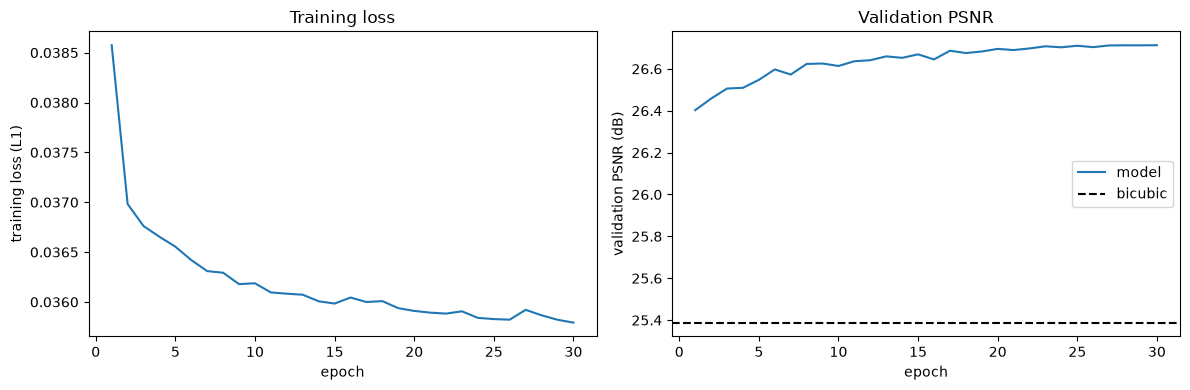

In [9]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(range(1, num_epochs + 1), train_losses)
plt.xlabel('epoch')
plt.ylabel('training loss (L1)')
plt.title('Training loss')
plt.subplot(1, 2, 2)
plt.plot(range(1, num_epochs + 1), val_psnrs, label='model')
plt.axhline(bicubic_psnr, linestyle='--', color='k', label='bicubic')
plt.xlabel('epoch')
plt.ylabel('validation PSNR (dB)')
plt.title('Validation PSNR')
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
# Time one frame
sr_model.eval()
x = torch.rand(1, 3, 32, 32).to(device)
with torch.no_grad():
    for i in range(10):
        sr_model(x)                       # warm-up
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.time()
    for i in range(100):
        sr_model(x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
ms_per_frame = (time.time() - start) / 100 * 1000

print(f'Bicubic: PSNR {bicubic_psnr:.2f} dB, SSIM {bicubic_ssim:.4f}')
print(f'Model:   PSNR {val_psnr:.2f} dB, SSIM {val_ssim:.4f}')
print(f'Parameters: {count_model_parameters(sr_model)}, time per frame: {ms_per_frame:.2f} ms')

Bicubic: PSNR 25.39 dB, SSIM 0.6062
Model:   PSNR 26.71 dB, SSIM 0.6782
Parameters: 245507, time per frame: 0.46 ms


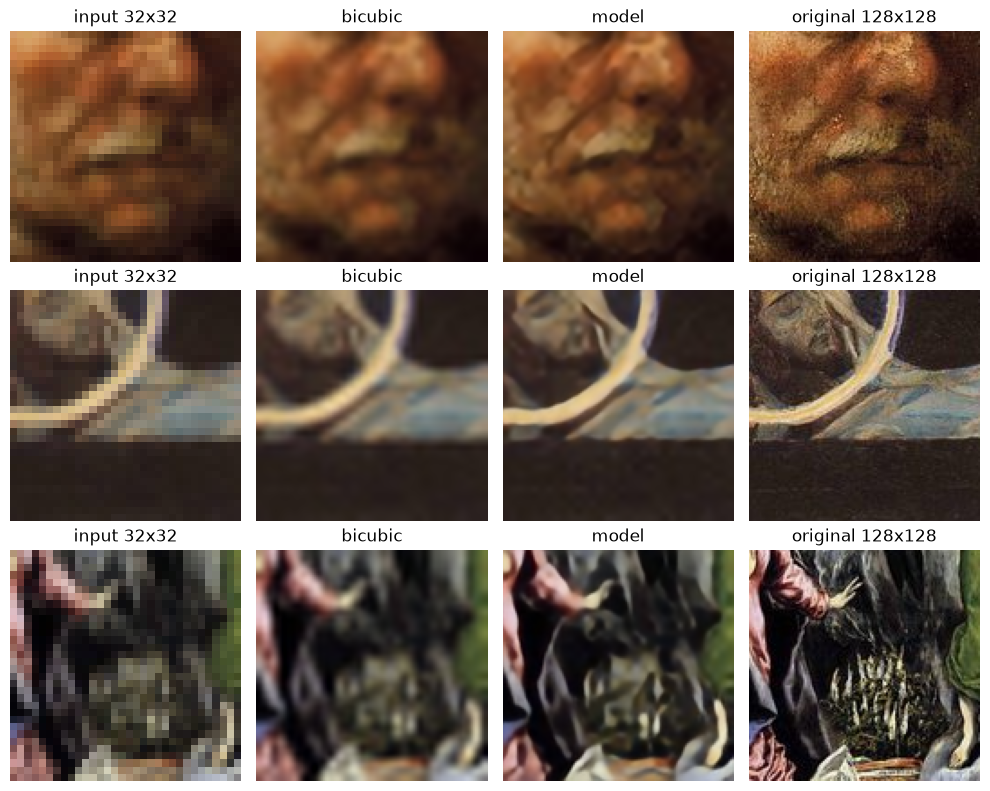

In [11]:
# Example images: input, bicubic, model, original
plt.figure(figsize=(10, 8))
titles = ['input 32x32', 'bicubic', 'model', 'original 128x128']
with torch.no_grad():
    for row in range(3):
        lr, hr = validation_dataset[row * 50]
        lr_batch = lr.unsqueeze(0).to(device)          # add a batch dimension
        images = [lr, bicubic(lr_batch)[0].cpu(), sr_model(lr_batch)[0].cpu(), hr]
        for col in range(4):
            plt.subplot(3, 4, row * 4 + col + 1)
            plt.imshow(images[col].permute(1, 2, 0).numpy())
            plt.title(titles[col])
            plt.axis('off')
plt.tight_layout()
plt.show()

# IMPORTANT
Make sure your model definition in `models.py` has the class name
`SuperResolutionModel` and make sure you save your weights as `model.pth` e.g.
`torch.save(model, 'model.pth')`.

**DO NOT** submit a model which has more than 5 Million parameters. We will
reject in the backend.

In [12]:
sr_model = sr_model.cpu()
total_params = count_model_parameters(sr_model)
if total_params > 5000000:
    print("Model greater than 5 million params!! Reduce model complexity!!")
else:
    torch.save(sr_model, 'model.pth')
    print('Saved model.pth')

Saved model.pth


# Load and test the saved model
As in Lab 5: reload `model.pth` and check it gives the same result.

In [13]:
loaded = torch.load('model.pth', weights_only=False)
loaded.to(device)
loaded.eval()
loaded_psnr, loaded_ssim = evaluate(loaded)
print(f'Reloaded model: PSNR {loaded_psnr:.2f} dB, SSIM {loaded_ssim:.4f}')

Reloaded model: PSNR 26.71 dB, SSIM 0.6782


# References
- Lab 7 instructions and starter notebook; F. Pitié, 4C16/5C16 lecture handouts 04 (evaluation), 05 (feedforward networks), 06 (CNNs), 07 (advances in architectures and training).
- J. Kim, J. K. Lee, K. M. Lee. *Accurate Image Super-Resolution Using Very Deep Convolutional Networks (VDSR).* CVPR 2016.
- B. Lim et al. *Enhanced Deep Residual Networks for Single Image Super-Resolution (EDSR).* CVPR Workshops 2017.
- K. He et al. *Deep Residual Learning for Image Recognition.* CVPR 2016.
- I. Loshchilov, F. Hutter. *SGDR: Stochastic Gradient Descent with Warm Restarts.* ICLR 2017.
- A. Odena, V. Dumoulin, C. Olah. *Deconvolution and Checkerboard Artifacts.* Distill 2016.
- Z. Wang et al. *Image Quality Assessment: From Error Visibility to Structural Similarity (SSIM).* IEEE TIP 2004.